# A-B01: 뇌동맥류 이진 nnU-Net DiceCE noSmooth

기존 팀원용 동맥류 폴더와 분리된 Dataset503 이진 분할 baseline입니다.

- 데이터: `Dataset503_TopAneuMRABinary` (background=0, aneurysm=1)
- 모델: standard nnU-Net `3d_fullres`
- loss/optimizer: nnU-Net 기본 Dice+CE / SGD
- 학습: 300 epochs, fold 0
- epoch 195부터 매 epoch checkpoint 보관, 200 epoch부터 10 epoch마다 full-volume validation
- macro Dice Top-3와 각 ±5 epoch checkpoint 보존 및 종료 후 재검증
- 결과: `runs/aneurysm_binary/nnunet`
- 다시 실행하면 `checkpoint_latest.pth`에서 자동 재개합니다.

## 1. 독립 경로 설정

In [1]:
from pathlib import Path
import json
import subprocess
import time

ROOT = Path("/home/stu03/workspace/model")
CONFIG = ROOT / "configs/experiments/aneurysm_binary/A-B01.yaml"
DATA_ROOT = Path("/home/stu03/workspace/datasets/aneurysm/v2/model_ready/nnunet")
RESULTS_ROOT = ROOT / "runs/aneurysm_binary/nnunet"
PYTHON_BIN = ROOT / ".venv/bin/python"
LAUNCHER = ROOT / "scripts/aneurysm_binary/training/run_a_b01.py"

DATASET_NAME = "Dataset503_TopAneuMRABinary"
TRAINER = "nnUNetTrainerAneurysmBinaryBaseline"
FOLD_DIR = RESULTS_ROOT / DATASET_NAME / f"{TRAINER}__AneurysmBinaryPlansDiceCENoSmoothV1__3d_fullres/fold_0"
PROGRESS_FILE = FOLD_DIR / "progress.json"
LOG_FILE = ROOT / "runs/aneurysm_binary/A-B01/train.log"
PID_FILE = ROOT / "runs/aneurysm_binary/A-B01/train.pid"

for name, path in {
    "config": CONFIG,
    "python": PYTHON_BIN,
    "launcher": LAUNCHER,
    "preprocessed": DATA_ROOT / "nnUNet_preprocessed" / DATASET_NAME,
}.items():
    print(f"{name:12s}: {path.exists()}  {path}")

config      : True  /home/stu03/workspace/model/configs/experiments/aneurysm_binary/A-B01.yaml
python      : True  /home/stu03/workspace/model/.venv/bin/python
launcher    : True  /home/stu03/workspace/model/scripts/aneurysm_binary/training/run_a_b01.py
preprocessed: True  /home/stu03/workspace/datasets/aneurysm/v2/model_ready/nnunet/nnUNet_preprocessed/Dataset503_TopAneuMRABinary


## 2. 실행 전 dry-run

파일을 만들거나 GPU를 사용하지 않고, 실행 명령과 출력 폴더만 확인합니다.

In [2]:
base_command = [
    str(PYTHON_BIN), str(LAUNCHER),
    "--config", str(CONFIG),
    "--data-root", str(DATA_ROOT),
    "--results-root", str(RESULTS_ROOT),
    "--python-bin", str(PYTHON_BIN),
]
subprocess.run(base_command + ["--dry-run"], cwd=ROOT, check=True)

{
  "experiment": "A-B01",
  "mode": "new",
  "output_folder": "/home/stu03/workspace/model/runs/aneurysm_binary/nnunet/Dataset503_TopAneuMRABinary/nnUNetTrainerAneurysmBinaryBaseline__AneurysmBinaryPlansDiceCENoSmoothV1__3d_fullres/fold_0",
  "prepare": [
    "/home/stu03/workspace/model/.venv/bin/python",
    "/home/stu03/workspace/model/scripts/aneurysm_binary/preprocessing/prepare_a_b00_plans.py",
    "--config",
    "/home/stu03/workspace/model/configs/experiments/aneurysm_binary/A-B01.yaml",
    "--data-root",
    "/home/stu03/workspace/datasets/aneurysm/v2/model_ready/nnunet"
  ],
  "train": [
    "/home/stu03/workspace/model/.venv/bin/nnUNetv2_train",
    "503",
    "3d_fullres",
    "0",
    "-tr",
    "nnUNetTrainerAneurysmBinaryBaseline",
    "-p",
    "AneurysmBinaryPlansDiceCENoSmoothV1",
    "-device",
    "cuda"
  ],
  "post_training_top3_neighborhood": [
    "/home/stu03/workspace/model/.venv/bin/python",
    "/home/stu03/workspace/model/scripts/aneurysm_binary/validati

CompletedProcess(args=['/home/stu03/workspace/model/.venv/bin/python', '/home/stu03/workspace/model/scripts/aneurysm_binary/training/run_a_b01.py', '--config', '/home/stu03/workspace/model/configs/experiments/aneurysm_binary/A-B01.yaml', '--data-root', '/home/stu03/workspace/datasets/aneurysm/v2/model_ready/nnunet', '--results-root', '/home/stu03/workspace/model/runs/aneurysm_binary/nnunet', '--python-bin', '/home/stu03/workspace/model/.venv/bin/python', '--dry-run'], returncode=0)

## 3. GPU 확인

In [3]:
subprocess.run(["nvidia-smi"], check=False)

Mon Sep  7 15:36:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.84                 Driver Version: 595.84         CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5090        Off |   00000000:01:00.0 Off |                  N/A |
|  0%   40C    P8             13W /  575W |   12528MiB /  32607MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

CompletedProcess(args=['nvidia-smi'], returncode=0)

## 4. 학습 시작 또는 재개

이 셀은 학습을 백그라운드로 시작하므로 다음 진행률 셀을 바로 실행할 수 있습니다. 기존 `checkpoint_latest.pth`가 있으면 launcher가 자동으로 `--c`를 붙여 재개합니다. 이미 실행 중인 PID가 있으면 중복 실행하지 않습니다.

In [4]:
LOG_FILE.parent.mkdir(parents=True, exist_ok=True)

def pid_is_running(pid_file):
    if not pid_file.is_file():
        return False
    try:
        pid = int(pid_file.read_text().strip())
        return subprocess.run(["kill", "-0", str(pid)], capture_output=True).returncode == 0
    except (ValueError, OSError):
        return False

if pid_is_running(PID_FILE):
    print("이미 실행 중입니다. PID:", PID_FILE.read_text().strip())
else:
    log_handle = LOG_FILE.open("a", encoding="utf-8")
    process = subprocess.Popen(
        base_command,
        cwd=ROOT,
        stdout=log_handle,
        stderr=subprocess.STDOUT,
        start_new_session=True,
    )
    PID_FILE.write_text(str(process.pid), encoding="utf-8")
    print("A-B01 시작 PID:", process.pid)
    print("로그:", LOG_FILE)

A-B01 시작 PID: 3862576
로그: /home/stu03/workspace/model/runs/aneurysm_binary/A-B01/train.log


## 5. 실시간 진행률

중단하려면 이 셀의 정지 버튼만 누르세요. 학습 프로세스는 계속 실행됩니다.

In [5]:
from IPython.display import clear_output, display
import pandas as pd

def read_json(path):
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

def format_time(seconds):
    if seconds is None:
        return "-"
    seconds = int(seconds)
    hours, remainder = divmod(seconds, 3600)
    minutes, seconds = divmod(remainder, 60)
    return f"{hours:02d}:{minutes:02d}:{seconds:02d}"

def pid_is_running(pid_file):
    if not pid_file.is_file():
        return False
    try:
        pid = int(pid_file.read_text(encoding="utf-8").strip())
        return subprocess.run(
            ["kill", "-0", str(pid)], capture_output=True
        ).returncode == 0
    except (ValueError, OSError):
        return False

while True:
    clear_output(wait=True)
    p = read_json(PROGRESS_FILE)
    running = pid_is_running(PID_FILE)
    status = p.get("status", "starting" if running else "not_started")
    row = {
        "실험": "A-B01",
        "상태": status,
        "Epoch": f"{p.get('current_epoch', 0)}/{p.get('total_epochs', 300)}",
        "진행률(%)": p.get("progress_percent", 0),
        "ETA": format_time(p.get("eta_seconds")),
        "Train Loss": p.get("train_loss"),
        "Val Loss": p.get("val_loss"),
        "Dice": p.get("pseudo_dice"),
        "Recall": p.get("pseudo_recall"),
        "Composite": p.get("composite"),
        "Best Dice": p.get("best_dice"),
        "Best Recall": p.get("best_recall"),
        "Best Composite": p.get("best_composite"),
        "Full Macro Dice": p.get("full_macro_dice"),
        "Best Full Macro Dice": p.get("best_full_macro_dice"),
        "Best Epoch": p.get("best_full_macro_epoch"),
        "Top-3 Epoch": p.get("top_full_macro_epochs"),
        "보존 checkpoint": p.get("retained_epoch_checkpoints"),
        "PID 실행 중": running,
    }
    display(pd.DataFrame([row]))
    print("로그 마지막 15줄:")
    if LOG_FILE.is_file():
        print("".join(LOG_FILE.read_text(encoding="utf-8", errors="replace").splitlines(True)[-15:]))
    if status == "completed" or (not running and p):
        print("학습 프로세스가 종료되었습니다. 아래 결과 확인 셀을 실행하세요.")
        break
    time.sleep(10)

,실험,상태,Epoch,진행률(%),ETA,Train Loss,Val Loss,Dice,Recall,Composite,Best Dice,Best Recall,Best Composite,Full Macro Dice,Best Full Macro Dice,Best Epoch,Top-3 Epoch,보존 checkpoint,PID 실행 중
0,A-B01,completed,300/300,100.0,00:00:00,-0.44583,None,0.766213,0.770957,0.768585,0.858766,0.909932,0.884349,0.479699,0.5161,270,"[270, 280, 300]",27,True


로그 마지막 15줄:
2026-09-08 00:37:53.381744: topaneu_center5_mr_470, shape torch.Size([1, 209, 455, 358]), rank 0
2026-09-08 00:38:04.579669: predicting topaneu_center5_mr_481
2026-09-08 00:38:04.624539: topaneu_center5_mr_481, shape torch.Size([1, 192, 485, 377]), rank 0
2026-09-08 00:38:15.823768: predicting topaneu_center5_mr_485
2026-09-08 00:38:15.868297: topaneu_center5_mr_485, shape torch.Size([1, 192, 453, 388]), rank 0
2026-09-08 00:38:35.151803: Validation complete
2026-09-08 00:38:35.151875: Mean Validation Dice:  0.3689990176707585
2026-09-08 00:38:35.173303: Full-volume epoch 300: positive macro Dice=0.479699
2026-09-08 00:38:35.260523: Training done.
2026-09-08 00:38:35.263134: Using splits from existing split file: /home/stu03/workspace/datasets/aneurysm/v2/model_ready/nnunet/nnUNet_preprocessed/Dataset503_TopAneuMRABinary/splits_final.json
2026-09-08 00:38:35.263225: The split file contains 1 splits.
2026-09-08 00:38:35.263241: Desired fold for training: 0
2026-09-08 00:38:3

## 6. 결과와 checkpoint 확인

In [ ]:
print("결과 폴더:", FOLD_DIR)
if not FOLD_DIR.is_dir():
    print("아직 결과 폴더가 없습니다.")
else:
    for path in sorted(FOLD_DIR.iterdir()):
        if path.is_file():
            print(f"{path.name:35s} {path.stat().st_size / 1024**2:9.2f} MB")

summary = FOLD_DIR / "validation" / "summary.json"
print("Full-volume validation summary:", summary.exists(), summary)

결과 폴더: /home/stu03/workspace/model/runs/aneurysm_binary/nnunet/Dataset503_TopAneuMRABinary/nnUNetTrainerAneurysmBinaryBaseline__AneurysmBinaryPlansDiceCENoSmoothV1__3d_fullres/fold_0
checkpoint_best.pth                    235.09 MB
checkpoint_best_composite.pth          235.09 MB
checkpoint_best_dice.pth               235.09 MB
checkpoint_best_full_macro.pth         235.08 MB
checkpoint_best_recall.pth             235.09 MB
checkpoint_final.pth                   235.09 MB
custom_metrics.json                      0.00 MB
debug.json                               0.02 MB
full_validation_history.json             0.01 MB
ich_config.json                          0.00 MB
progress.json                            0.00 MB
progress.png                             1.11 MB
training_log_2026_9_7_15_36_09.txt       0.22 MB
Full-volume validation summary: False /home/stu03/workspace/model/runs/aneurysm_binary/nnunet/Dataset503_TopAneuMRABinary/nnUNetTrainerAneurysmBinaryBaseline__AneurysmBinaryPlansDi

## 7. 재개 방법

학습이 서버 종료나 OOM으로 중단되면 **4번 셀을 다시 실행**하면 됩니다. `checkpoint_latest.pth`가 존재할 때 자동 재개합니다. 새로 처음부터 돌리고 싶을 때만 기존 결과 폴더를 별도로 백업한 뒤 `--no-resume`을 사용하세요.

## 8. Best full-volume 병변 크기별 Dice와 탐지율

현재 `Best Full Macro Dice` epoch의 저장된 예측을 CPU에서 분석합니다.

- GT와 예측은 3D 26-connectivity connected component로 분리
- GT 병변과 1 voxel 이상 겹친 예측 component를 탐지로 판정
- Lesion Dice는 각 GT 병변과 겹치는 예측 component들의 합집합으로 계산
- 탐지하지 못한 GT 병변의 Dice는 0
- 결과는 `lesion_analysis/`에 CSV와 PNG로 저장

In [15]:
# Best epoch 선택 및 입력 파일 확인
import gc
import numpy as np
import nibabel as nib
from scipy import ndimage

BEST_INFO = FOLD_DIR / "best_full_macro.json"
HISTORY_FILE = FOLD_DIR / "full_validation_history.json"

if BEST_INFO.is_file():
    best_info = read_json(BEST_INFO)
    best_epoch = int(best_info["epoch"])
elif HISTORY_FILE.is_file():
    history = read_json(HISTORY_FILE)
    if not history:
        raise RuntimeError("full-volume validation history가 비어 있습니다.")
    best_info = max(history, key=lambda x: float(x["macro_dice_positive"]))
    best_epoch = int(best_info["epoch"])
else:
    progress = read_json(PROGRESS_FILE)
    best_epoch = progress.get("best_full_macro_epoch")
    if best_epoch is None:
        raise RuntimeError("아직 full-volume validation 결과가 없습니다.")
    best_epoch = int(best_epoch)
    best_info = {"epoch": best_epoch, "macro_dice_positive": progress.get("best_full_macro_dice")}

PREDICTION_DIR = FOLD_DIR / "full_validation" / f"epoch_{best_epoch:04d}"
SUMMARY_FILE = PREDICTION_DIR / "summary.json"
ANALYSIS_DIR = FOLD_DIR / "lesion_analysis" / f"epoch_{best_epoch:04d}"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

if not SUMMARY_FILE.is_file():
    raise FileNotFoundError(f"summary.json 없음: {SUMMARY_FILE}")

print("Best epoch       :", best_epoch)
print("Best macro Dice  :", best_info.get("macro_dice_positive"))
print("Prediction folder:", PREDICTION_DIR)
print("Analysis folder  :", ANALYSIS_DIR)

Best epoch       : 270
Best macro Dice  : 0.5160995437766565
Prediction folder: /home/stu03/workspace/model/runs/aneurysm_binary/nnunet/Dataset503_TopAneuMRABinary/nnUNetTrainerAneurysmBinaryBaseline__AneurysmBinaryPlansDiceCENoSmoothV1__3d_fullres/fold_0/full_validation/epoch_0270
Analysis folder  : /home/stu03/workspace/model/runs/aneurysm_binary/nnunet/Dataset503_TopAneuMRABinary/nnUNetTrainerAneurysmBinaryBaseline__AneurysmBinaryPlansDiceCENoSmoothV1__3d_fullres/fold_0/lesion_analysis/epoch_0270


In [16]:
# GT 병변 component별 Dice 및 탐지 여부 계산
summary = read_json(SUMMARY_FILE)
structure = ndimage.generate_binary_structure(rank=3, connectivity=3)  # 26-connectivity
lesion_rows = []

for case_item in summary.get("metric_per_case", []):
    reference_path = Path(case_item["reference_file"])
    prediction_path = PREDICTION_DIR / Path(case_item["prediction_file"]).name
    if not prediction_path.is_file():
        raise FileNotFoundError(f"예측 파일 없음: {prediction_path}")

    gt_image = nib.load(reference_path)
    pred_image = nib.load(prediction_path)
    gt = np.asanyarray(gt_image.dataobj) > 0
    pred = np.asanyarray(pred_image.dataobj) > 0
    if gt.shape != pred.shape:
        raise ValueError(f"shape 불일치: {reference_path.name}: GT={gt.shape}, pred={pred.shape}")

    voxel_volume_ml = abs(float(np.linalg.det(gt_image.affine[:3, :3]))) / 1000.0
    gt_labels, gt_count = ndimage.label(gt, structure=structure)
    pred_labels, _ = ndimage.label(pred, structure=structure)

    for lesion_id, lesion_slice in enumerate(ndimage.find_objects(gt_labels), start=1):
        if lesion_slice is None:
            continue
        gt_component = gt_labels[lesion_slice] == lesion_id
        overlapping_pred_ids = np.unique(pred_labels[lesion_slice][gt_component])
        overlapping_pred_ids = overlapping_pred_ids[overlapping_pred_ids > 0]
        detected = len(overlapping_pred_ids) > 0

        # 겹친 예측 component 전체와 현재 GT component의 Dice
        if detected:
            pred_component = np.isin(pred_labels, overlapping_pred_ids)
            intersection = int(np.count_nonzero(pred_component & (gt_labels == lesion_id)))
            denominator = int(pred_component.sum()) + int(gt_component.sum())
            lesion_dice = 2.0 * intersection / denominator if denominator else 0.0
        else:
            intersection = 0
            lesion_dice = 0.0

        volume_ml = float(gt_component.sum() * voxel_volume_ml)
        lesion_rows.append({
            "case_id": prediction_path.name.removesuffix(".nii.gz"),
            "lesion_id": lesion_id,
            "gt_voxels": int(gt_component.sum()),
            "gt_volume_ml": volume_ml,
            "detected": bool(detected),
            "overlap_voxels": intersection,
            "lesion_dice": float(lesion_dice),
        })

    del gt, pred, gt_labels, pred_labels
    gc.collect()

lesion_df = pd.DataFrame(lesion_rows)
if lesion_df.empty:
    raise RuntimeError("GT 병변 component가 없습니다.")

lesion_df.to_csv(ANALYSIS_DIR / "lesion_size_metrics.csv", index=False)
display(lesion_df.head())
print("전체 병변:", len(lesion_df))
print("탐지 병변:", int(lesion_df["detected"].sum()))
print("전체 병변 탐지율:", f"{lesion_df['detected'].mean():.4f}")
print("전체 병변 평균 Dice:", f"{lesion_df['lesion_dice'].mean():.4f}")

,case_id,lesion_id,gt_voxels,gt_volume_ml,detected,overlap_voxels,lesion_dice
0,topaneu_center1_mr_085,1,1206,0.036354,False,0,0.000000
1,topaneu_center1_mr_085,2,158,0.004763,False,0,0.000000
2,topaneu_center1_mr_184,1,192,0.007383,False,0,0.000000
3,topaneu_center1_mr_264,1,361,0.023697,False,0,0.000000
4,topaneu_center1_mr_301,1,14619,0.645305,True,12032,0.818949


전체 병변: 40
탐지 병변: 26
전체 병변 탐지율: 0.6500
전체 병변 평균 Dice: 0.4832


In [11]:
# 병변 크기별 요약
SIZE_LABELS = ["<0.01 mL", "0.01–0.05 mL", "0.05–0.1 mL", "0.1–0.5 mL", "≥0.5 mL"]
lesion_df["size_group"] = pd.cut(
    lesion_df["gt_volume_ml"],
    bins=[-np.inf, 0.01, 0.05, 0.1, 0.5, np.inf],
    labels=SIZE_LABELS,
    right=False,
)

size_summary = (
    lesion_df.groupby("size_group", observed=False)
    .agg(
        gt_lesions=("lesion_id", "size"),
        detected_lesions=("detected", "sum"),
        detection_rate=("detected", "mean"),
        mean_lesion_dice=("lesion_dice", "mean"),
        median_lesion_dice=("lesion_dice", "median"),
        mean_dice_detected_only=(
            "lesion_dice",
            lambda x: x[lesion_df.loc[x.index, "detected"]].mean(),
        ),
        median_volume_ml=("gt_volume_ml", "median"),
    )
    .reset_index()
)
size_summary["detected/total"] = (
    size_summary["detected_lesions"].astype(int).astype(str)
    + "/"
    + size_summary["gt_lesions"].astype(int).astype(str)
)
size_summary.to_csv(ANALYSIS_DIR / "lesion_size_summary.csv", index=False)
display(size_summary[[
    "size_group", "gt_lesions", "detected/total", "detection_rate",
    "mean_lesion_dice", "median_lesion_dice", "mean_dice_detected_only",
]])

,size_group,gt_lesions,detected/total,detection_rate,mean_lesion_dice,median_lesion_dice,mean_dice_detected_only
0,<0.01 mL,7,0/7,0.000000,0.000000,0.000000,NaN
1,0.01–0.05 mL,21,16/21,0.761905,0.537000,0.707819,0.704813
2,0.05–0.1 mL,4,2/4,0.500000,0.431566,0.400522,0.863132
3,0.1–0.5 mL,3,3/3,1.000000,0.665045,0.841158,0.665045
4,≥0.5 mL,5,5/5,1.000000,0.865631,0.871624,0.865631


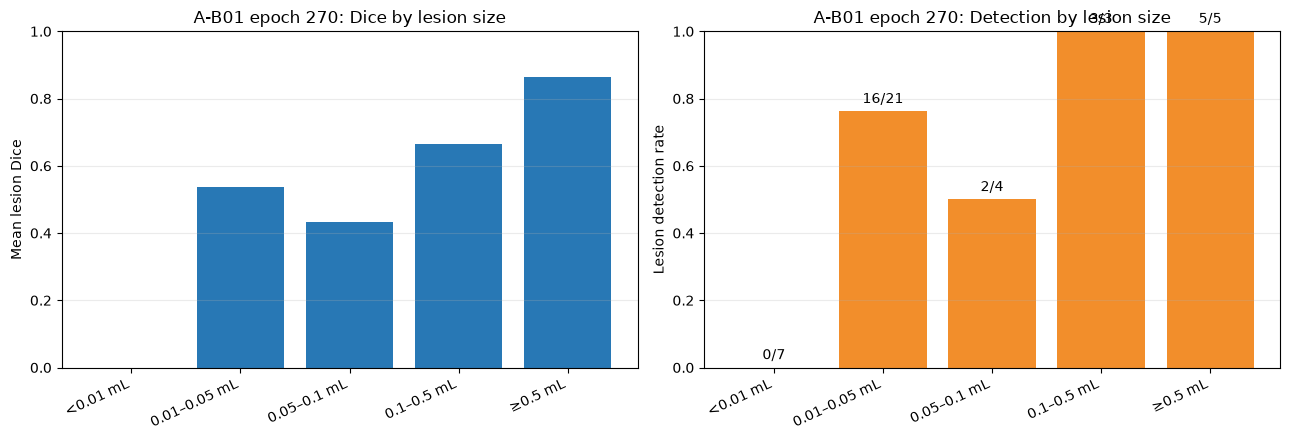

저장: /home/stu03/workspace/model/runs/aneurysm_binary/nnunet/Dataset503_TopAneuMRABinary/nnUNetTrainerAneurysmBinaryBaseline__AneurysmBinaryPlansDiceCENoSmoothV1__3d_fullres/fold_0/lesion_analysis/epoch_0270/lesion_size_dice_detection.png


In [12]:
# 병변 크기별 Dice와 탐지율 시각화
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(size_summary))

axes[0].bar(x, size_summary["mean_lesion_dice"], color="#2878B5")
axes[0].set_xticks(x, size_summary["size_group"], rotation=25, ha="right")
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Mean lesion Dice")
axes[0].set_title(f"A-B01 epoch {best_epoch}: Dice by lesion size")
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(x, size_summary["detection_rate"], color="#F28E2B")
axes[1].set_xticks(x, size_summary["size_group"], rotation=25, ha="right")
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Lesion detection rate")
axes[1].set_title(f"A-B01 epoch {best_epoch}: Detection by lesion size")
axes[1].grid(axis="y", alpha=0.25)
for index, row in size_summary.iterrows():
    axes[1].text(index, row["detection_rate"] + 0.025, row["detected/total"], ha="center")

fig.tight_layout()
figure_path = ANALYSIS_DIR / "lesion_size_dice_detection.png"
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()
print("저장:", figure_path)